In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

In [ ]:
X, y = load_diabetes(return_X_y=True)
print(X.shape, y.shape)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size= 0.2 ,random_state=42)
print(X_train.shape)
print(X_test.shape)


(442, 10) (442,)


AttributeError: 'numpy.ndarray' object has no attribute 'head'

In [3]:
a = X_train.mean(axis = 0)
a1 = X_train.std(axis = 0)

X_train_s = (X_train - a)/a1
print(X_train_s.mean(axis= 0))
print(X_train_s.std(axis = 0))

[ 2.76769479e-17  9.12081238e-17 -6.69907944e-17  3.33381418e-17
 -2.67334156e-17 -1.79271140e-17  4.40315081e-17  1.82730758e-16
  2.03645725e-17 -5.75947851e-17]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [4]:
X_test_s = (X_test - a)/a1
print(X_test_s.mean(axis = 0))
print(X_test_s.std(axis= 0))

[-0.15475875 -0.0191956  -0.18259061 -0.1210162   0.0578151   0.08415825
  0.10455509 -0.03918665 -0.1264499  -0.19438961]
[1.12390087 0.99867091 1.02408276 0.90468304 0.98262382 0.99732055
 1.05660166 0.98292114 0.97298266 0.9041655 ]


In [5]:

def cost(w , b):
    Preds = (X_train_s @ w) + b
    errors = Preds - y_train
    J = sum((errors ** 2)/(2*len(X_train_s)))
    return J

def gradients(w, b):
    Preds = (X_train_s @ w) + b
    errors = Preds - y_train
    grad_w = (1/len(X_train_s)) * X_train_s.T @ errors
    grad_b = sum((1/len(X_train_s)) * errors)
    return grad_w, grad_b



In [6]:
print(cost(np.zeros(10), 0))
print(gradients(np.zeros(10), 0))

14855.661473087814
(array([-15.31817593,  -0.55471453, -47.14112176, -34.67040988,
       -15.55495448, -12.07634942,  29.93324357, -33.13661938,
       -43.04336561, -30.42929502]), np.float64(-153.73654390934846))


In [ ]:
def grad(alpha, n_iter):
    w = np.zeros(10)
    b = 0
    J1 = []
    for i in range(n_iter):
        wb = gradients(w,b)
        w1 = wb[0]
        b1 = wb[1]
        J1.append(cost(w,b))
        w = w - alpha * w1
        b = b - alpha * b1
    return w, b, J1

w, b, J1 = grad(0.1, 5000)

print(J1[:3])
print(J1[-1])
print(b)
print(w)
print()
linreg = LinearRegression().fit(X_train_s, y_train)
print(linreg.intercept_)
print(linreg.coef_)

print(f'разница w и linreg.coef_: {w - linreg.coef_}')

[np.float64(14855.661473087814), np.float64(11882.554543066526), np.float64(9740.66503814955)]
1434.2763870594347
153.7365439093483
[  1.75599238 -11.51094842  25.61501676  16.82633082 -44.03862849
  24.32006465   7.49600128  13.08244352  35.00377243   2.35433417]

153.73654390934846
[  1.75375799 -11.51180908  25.60712144  16.82887167 -44.44885564
  24.64095356   7.67697768  13.1387839   35.16119521   2.35136365]
разница w и linreg.coef_: [ 0.00223438  0.00086066  0.00789533 -0.00254084  0.41022715 -0.32088891
 -0.1809764  -0.05634038 -0.15742278  0.00297051]


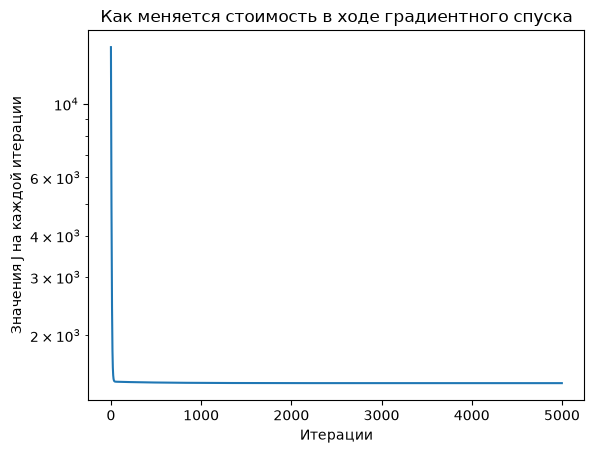

In [9]:
n = 5000

fig, ax = plt.subplots()
ax.plot(range(n), J1)
ax.set_title("Как меняется стоимость в ходе градиентного спуска")

ax.set_xlabel("Итерации")

ax.set_ylabel("Значения J на каждой итерации")
ax.set_yscale('log')
plt.show()

/var/folders/2_/8hp42lnx5tv0l1jwy3tp82_h0000gn/T/ipykernel_6912/827008401.py:4: RuntimeWarning: overflow encountered in square
  J = sum((errors ** 2)/(2*len(X_train_s)))
/Users/macbook/Desktop/project/.venv/lib/python3.15/site-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


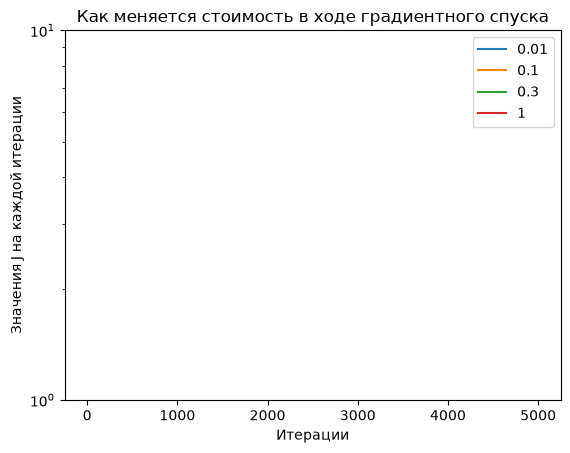

In [ ]:
fig, ax = plt.subplots()
ax.plot(range(n), grad(0.01, n)[2], label = '0.01')
ax.plot(range(n), grad(0.1, n)[2], label = '0.1')
ax.plot(range(n), grad(0.3, n)[2], label = '0.3')
ax.plot(range(n), grad(0.5, n)[2], label = '0.5')
ax.legend()
ax.set_title("Как меняется стоимость в ходе градиентного спуска")

ax.set_xlabel("Итерации")

ax.set_ylabel("Значения J на каждой итерации")
ax.set_yscale('log')
plt.show()

Вывод ко всей части 2 (сравнение со scikit-learn)
Результат спуска. J упала с 14 855.66 до 1 434.28 (train MSE ≈ 2868.6).
Совпадение со sklearn. b совпал почти точно (153.7365). Максимальное отклонение весов 0.41 (w[4], s1), у остальных меньше. Это ≈1% для самых больших весов.
Где расхождение и почему.Расхождения у s1, s2, s3. Возможно, из-за корреляции признаков спуск там идёт медленнее. Это можно проверить, увеличив число итераций: разница должна уменьшиться
Роль масштабирования.Признаки приведены к одному масштабу, это улучшает работу модели: ей не приходится „прыгать“ между большими и маленькими значениями, и шаг можно подбирать одинаковый для всех весов, поэтому один α подходит всем весам и спуск идёт быстро. Среднее и стандартное отклонение считались только по train.
Почему результат тот же, что у fit. fit находит минимум J по формуле сразу, градиентный спуск идёт к тому же минимуму шагами. Поверхность J для линейной регрессии выпуклая и с одним минимумом, поэтому оба метода приходят в одну точку.
